# Regresión: CatBoost

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from ModeladoRegresion import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_REG, VARIANTES, N_ITER_REG, RUTA_FASE1_REG,
    cargar_split, separar_x_y_reg, crear_cv_reg, resumen_target, dispositivo_reg, describir_espacio_reg,
    ejecutar_fase1_reg, formatear_tabla_cv_reg, tabla_hiperparametros_reg, graficar_variantes, evaluar_smearing,
    elegir_variante, guardar_fase1_reg, formatear_hiperparametros,
)

CLAVE = "catboost"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_reg(CLAVE),
}, name=NOMBRES_REG[CLAVE]).to_frame()

,CatBoost
USAR_GPU,False
GPU detectada por librería,ninguna
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y_reg(df_train)
cv = crear_cv_reg(SEED)

resumen_target(y_train)

,Filas,Media,Mediana,DE,Asimetría,Ceros (%),BDI ≥ 14 (%)
Conjunto,,,,,,,
Train,3848,7.3,5.0,7.75,1.9,10.5,16.4


### Variantes del Target

Se comparan cuatro variantes del target: nativo, sqrt y log1p (estas dos con corrección de smearing) y pérdida Poisson (`loss_function="Poisson"`). Su justificación y el sesgo de retransformación se explican en [Variantes del target](#mod-variantes) y [Sesgo de retransformación](#mod-smearing).

### Espacio de Búsqueda

Mismos rangos que en la clasificación (versión `Regressor`). Se exploraron 25 combinaciones por variante: iteraciones (200 a 800), profundidad (3 a 7), tasa de aprendizaje en escala logarítmica (0.01 a 0.2) y regularización L2 de las hojas (1 a 10).

In [4]:
describir_espacio_reg(CLAVE).style.set_caption(f"Combinaciones por variante: {N_ITER_REG[CLAVE]}")

,Valores
Hiperparámetro,
iterations,entero entre 200 y 800
depth,entero entre 3 y 7
learning_rate,log-uniforme entre 0.01 y 0.2
l2_leaf_reg,uniforme entre 1 y 10


### Validación Cruzada por Variante

In [5]:
tabla, pipelines, hiperparametros = ejecutar_fase1_reg(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo             RMSE = 6.8815 ± 0.4803  R² = 0.2052  (33 s)
✓ sqrt + smearing    RMSE = 6.8796 ± 0.4906  R² = 0.2058  (35 s)
✓ log1p + smearing   RMSE = 6.8837 ± 0.4847  R² = 0.2047  (35 s)
✓ Pérdida Poisson    RMSE = 6.8887 ± 0.4943  R² = 0.2037  (59 s)


In [6]:
vista = formatear_tabla_cv_reg(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
vista.rename(index=VARIANTES)

,RMSE,MAE,R²,Tiempo (s)
Variante,,,,
Nativo,6.881 ± 0.480,4.884 ± 0.186,0.205 ± 0.017,33.0
sqrt + smearing,6.880 ± 0.491,4.859 ± 0.182,0.206 ± 0.017,35.0
log1p + smearing,6.884 ± 0.485,4.877 ± 0.185,0.205 ± 0.020,35.0
Pérdida Poisson,6.889 ± 0.494,4.879 ± 0.186,0.204 ± 0.018,59.0


sqrt (6.880 ± 0.491) y el nativo (6.881 ± 0.480) obtienen el menor RMSE, con R² de 0.206 y 0.205. log1p (6.884) y la pérdida Poisson (6.889) quedan a menos de 0.01 puntos. CatBoost es el modelo con el menor RMSE de la fase 1, aunque su ventaja sobre la regresión lineal (6.900) es de solo 0.02 puntos.

In [7]:
# Mejores hiperparámetros por variante
tabla_hiperparametros_reg(hiperparametros)

,depth,iterations,l2_leaf_reg,learning_rate
Variante,,,,
Nativo,3,543,4.554,0.02409
sqrt + smearing,3,543,4.554,0.02409
log1p + smearing,3,356,8.220,0.01250
Pérdida Poisson,4,232,1.572,0.02539


El nativo y sqrt eligieron la misma configuración: 543 iteraciones de profundidad 3, `learning_rate` = 0.024 y `l2_leaf_reg` = 4.6. log1p prefiere menos iteraciones (356), más regularización (8.2) y una tasa de aprendizaje menor. La pérdida Poisson elige menos iteraciones (232) de profundidad 4 y es la más lenta (59 s frente a 33–35 s).

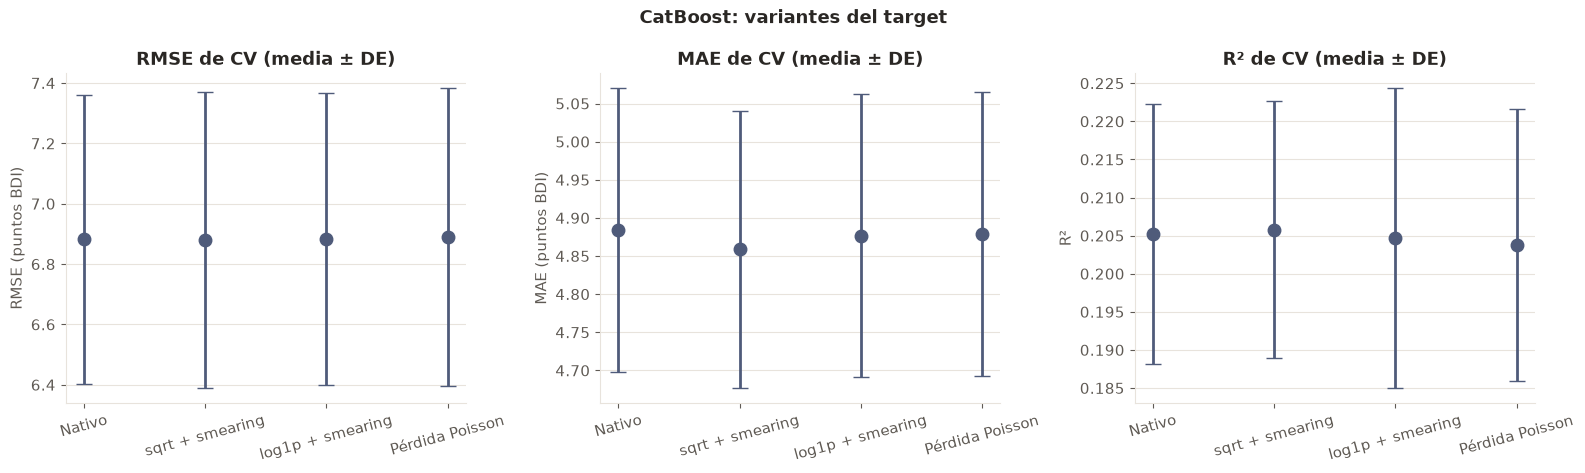

In [8]:
fig = graficar_variantes(tabla, NOMBRES_REG[CLAVE])
plt.show()

La gráfica muestra cuatro variantes equivalentes, con barras de desviación que se solapan por completo.

### Sesgo de Retransformación: Efecto del Smearing

In [9]:
variante_t, tabla_smearing = evaluar_smearing(tabla, pipelines, X_train, y_train, cv)
tabla_smearing.round(3)

,Media,Sesgo medio,RMSE,MAE,R²
Out-of-fold (sqrt + smearing),,,,,
BDI real,7.302,0.000,NaN,NaN,NaN
Sin smearing,5.821,-1.480,7.053,4.642,0.171
Con smearing,7.196,-0.106,6.897,4.859,0.207


Sin smearing, la media predicha con sqrt es 5.82, 1.48 puntos por debajo de la real; con la corrección queda en 7.20. El RMSE baja de 7.053 a 6.897 y el R² sube de 0.171 a 0.207, con un sesgo residual de −0.11 puntos.

### Selección del Mejor Modelo CatBoost

In [10]:
variante_ganadora, explicacion = elegir_variante(tabla)

pd.Series({
    "Variante ganadora": VARIANTES[variante_ganadora],
    "RMSE de CV": f"{tabla.loc[variante_ganadora, 'RMSE media']:.4f} ± {tabla.loc[variante_ganadora, 'RMSE DE']:.4f}",
    "MAE de CV": f"{tabla.loc[variante_ganadora, 'MAE media']:.4f} ± {tabla.loc[variante_ganadora, 'MAE DE']:.4f}",
    "R² de CV": f"{tabla.loc[variante_ganadora, 'R² media']:.4f} ± {tabla.loc[variante_ganadora, 'R² DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[variante_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_REG[CLAVE]).to_frame()

,CatBoost
Variante ganadora,Nativo
RMSE de CV,6.8815 ± 0.4803
MAE de CV,4.8838 ± 0.1864
R² de CV,0.2052 ± 0.0171
Hiperparámetros,"depth=3, iterations=543, l2_leaf_reg=4.554, learning_rate=0.02409"
Criterio,"El menor RMSE medio de CV es el de 'sqrt + smearing' (6.8796 ± 0.4906), pero 'Nativo' es más simple y su RMSE (6.8815) está a solo 0.0018 puntos, menos que la desviación estándar de CV de la ganadora (0.4906). Por la regla de empate se elige 'Nativo'."


sqrt tiene el menor RMSE medio (6.8796), pero el nativo está a solo 0.002 puntos (desviación entre folds: 0.491). Por la regla de empate se elige el nativo.

### Guardado

In [11]:
ganador = guardar_fase1_reg(
    CLAVE, tabla, variante_ganadora, pipelines[variante_ganadora],
    hiperparametros[variante_ganadora], explicacion,
)
print(f"✓ Guardado en {RUTA_FASE1_REG / CLAVE}: resultados_cv.csv, ganador.json y {ganador['archivo']}")

✓ Guardado en /workspace/data/processed/modelado/regresion/fase1/catboost: resultados_cv.csv, ganador.json y catboost_nativo.joblib
